In [1]:
# ChatGPT Model 6 and Claude Sonnet 5.5 were used to assist with code development, clean-up, and documentation

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm


def concentration_crlb(
    T_pM,
    kon_M_inv_s,
    koff_s_inv,
    f0,
    noise_sd=0.005,
    duration_s=30 * 60, # each estimation is done over a 30-minute interval
    sample_interval_s=60,
):

    # Kd in pM
    Kd_pM = (koff_s_inv / kon_M_inv_s) * 1e12

    # Total kinetic rate in s^-1
    rate_s_inv = (
        kon_M_inv_s * (T_pM * 1e-12)
        + koff_s_inv
    )

    # Sample at 60, 120, ..., 1800 seconds
    times_s = np.arange(
        sample_interval_s,
        duration_s + sample_interval_s,
        sample_interval_s,
    )

    # Equilibrium fraction bound
    f_eq = T_pM / (Kd_pM + T_pM)

    exponential = np.exp(-rate_s_inv * times_s)

    # Derivative of f(t) with respect to T in pM
    # f = f1-(f1-f0)e^-kt
    # f = T/(kd+T) * (1-e^-kt) + f0e^-kt
    # k = konT + koff
    # df/dT = kd/(kd+T)^2 + kontf1e^-kt - kd/(kd+T)^2e^-kt -kontf0e^-kt
    # df/dT = kd/(kd+T)^2 * (1-e^-kt) + (feq-f0)*kon*t*e^-kt --> matches
    df_dT_pM = (
        Kd_pM / (Kd_pM + T_pM) ** 2
        * (1.0 - exponential)
        +
        (f_eq - f0)
        * times_s
        * kon_M_inv_s
        * 1e-12
        * exponential
    )

    fisher_information = (
        np.sum(df_dT_pM**2) / noise_sd**2
    )

    if fisher_information <= 0 or not np.isfinite(fisher_information):
        return np.nan, np.nan

    sd_crlb_pM = 1.0 / np.sqrt(fisher_information)
    cv_crlb = sd_crlb_pM / T_pM

    return sd_crlb_pM, cv_crlb


# ============================================================
# Settings
# ============================================================
kon = 1e6  # M^-1 s^-1

koff_values = np.array([
    1e-2,
    1e-3,
    1e-4,
    1e-5,
    1e-6,
])

# Initial fraction-bound values to test
f0_values = np.linspace(0.0, 1.0, 101)

noise_sd = 0.005
cv_threshold = 0.10

# Candidate target concentrations in pM
T_test_pM = np.logspace(
    np.log10(0.01),
    np.log10(1e5),
    10000,
)


# ============================================================
# Find minimum T with CRLB CV < 10%
# for every koff and f0 combination
# ============================================================
results = []

for koff in koff_values:
    for f0 in f0_values:

        cv_values = np.array([
            concentration_crlb(
                T_pM=T,
                kon_M_inv_s=kon,
                koff_s_inv=koff,
                f0=f0,
                noise_sd=noise_sd,
                duration_s=30 * 60,
                sample_interval_s=60,
            )[1]
            for T in T_test_pM
        ])

        valid_indices = np.where(cv_values < cv_threshold)[0]

        if len(valid_indices) == 0:
            minimum_T_pM = np.nan
        else:
            minimum_T_pM = T_test_pM[valid_indices[0]]

        results.append({
            "koff": koff,
            "f0": f0,
            "minimum_T_pM": minimum_T_pM,
        })


# Convert results to arrays for plotting
koff_plot = np.array([row["koff"] for row in results])
f0_plot = np.array([row["f0"] for row in results])
T_color = np.array([row["minimum_T_pM"] for row in results])

valid = np.isfinite(T_color)


# ============================================================
# Print threshold concentrations
# ============================================================
print("Minimum T with CRLB CV < 10%\n")

for row in results:
    if np.isclose(row["f0"] % 0.1, 0, atol=1e-8):
        if np.isfinite(row["minimum_T_pM"]):
            print(
                f"koff = {row['koff']:.0e} s^-1, "
                f"f0 = {row['f0']:.2f}: "
                f"T_min = {row['minimum_T_pM']:.3f} pM"
            )
        else:
            print(
                f"koff = {row['koff']:.0e} s^-1, "
                f"f0 = {row['f0']:.2f}: "
                "no valid T in search range"
            )
            

Minimum T with CRLB CV < 10%

koff = 1e-02 s^-1, f0 = 0.00: T_min = 96.249 pM
koff = 1e-02 s^-1, f0 = 0.10: T_min = 96.716 pM
koff = 1e-02 s^-1, f0 = 0.20: T_min = 97.185 pM
koff = 1e-02 s^-1, f0 = 0.40: T_min = 97.971 pM
koff = 1e-02 s^-1, f0 = 0.70: T_min = 99.083 pM
koff = 1e-02 s^-1, f0 = 0.80: T_min = 99.563 pM
koff = 1e-03 s^-1, f0 = 0.00: T_min = 15.571 pM
koff = 1e-03 s^-1, f0 = 0.10: T_min = 16.422 pM
koff = 1e-03 s^-1, f0 = 0.20: T_min = 17.375 pM
koff = 1e-03 s^-1, f0 = 0.40: T_min = 19.608 pM
koff = 1e-03 s^-1, f0 = 0.70: T_min = 24.179 pM
koff = 1e-03 s^-1, f0 = 0.80: T_min = 26.166 pM
koff = 1e-04 s^-1, f0 = 0.00: T_min = 9.296 pM
koff = 1e-04 s^-1, f0 = 0.10: T_min = 10.257 pM
koff = 1e-04 s^-1, f0 = 0.20: T_min = 11.463 pM
koff = 1e-04 s^-1, f0 = 0.40: T_min = 14.932 pM
koff = 1e-04 s^-1, f0 = 0.70: T_min = 27.419 pM
koff = 1e-04 s^-1, f0 = 0.80: T_min = 37.972 pM
koff = 1e-05 s^-1, f0 = 0.00: T_min = 8.744 pM
koff = 1e-05 s^-1, f0 = 0.10: T_min = 9.710 pM
koff = 1e-05 

In [2]:
print("\nBest f0 for each koff")
print("---------------------")

T_matrix = np.full(
    (len(f0_values), len(koff_values)),
    np.nan,
)
for row in results:
    koff_index = np.where(
        np.isclose(koff_values, row["koff"])
    )[0][0]

    f0_index = np.where(
        np.isclose(f0_values, row["f0"])
    )[0][0]
    

    T_matrix[f0_index, koff_index] = row["minimum_T_pM"]


for j, koff in enumerate(koff_values):

    column = T_matrix[:, j]


    valid = np.isfinite(column)

    if not np.any(valid):

        print(
            f"koff = {koff:.0e} s^-1: "
            "no f0 achieved CV < 10%"
        )
        continue

    # Index of the smallest detectable concentration
    valid_indices = np.where(valid)[0]
    best_local_index = np.argmin(column[valid])
    best_index = valid_indices[best_local_index]

    best_f0 = f0_values[best_index]
    best_T = column[best_index]

    print(
        f"koff = {koff:.0e} s^-1: "
        f"best f0 = {best_f0:.3f}, "
        f"minimum T = {best_T:.3f} pM"
    )


Best f0 for each koff
---------------------
koff = 1e-02 s^-1: best f0 = 0.000, minimum T = 96.249 pM
koff = 1e-03 s^-1: best f0 = 0.000, minimum T = 15.571 pM
koff = 1e-04 s^-1: best f0 = 0.000, minimum T = 9.296 pM
koff = 1e-05 s^-1: best f0 = 0.000, minimum T = 8.744 pM
koff = 1e-06 s^-1: best f0 = 0.000, minimum T = 8.687 pM


In [3]:
print("\nAll f0 values achieving CRLB CV < 10%")
print("---------------------------------------")

for koff in koff_values:

    valid_rows = [
        row for row in results
        if np.isclose(row["koff"], koff)
        and np.isfinite(row["minimum_T_pM"])
    ]

    print(f"\nkoff = {koff:.0e} s^-1")

    if not valid_rows:
        print("  No f0 values achieved CV < 10%")
        continue

    for row in valid_rows:
        print(
            f"  f0 = {row['f0']:.2f}: "
            f"minimum T = {row['minimum_T_pM']:.3f} pM"
        )


All f0 values achieving CRLB CV < 10%
---------------------------------------

koff = 1e-02 s^-1
  f0 = 0.00: minimum T = 96.249 pM
  f0 = 0.01: minimum T = 96.405 pM
  f0 = 0.02: minimum T = 96.405 pM
  f0 = 0.03: minimum T = 96.405 pM
  f0 = 0.04: minimum T = 96.560 pM
  f0 = 0.05: minimum T = 96.560 pM
  f0 = 0.06: minimum T = 96.560 pM
  f0 = 0.07: minimum T = 96.560 pM
  f0 = 0.08: minimum T = 96.716 pM
  f0 = 0.09: minimum T = 96.716 pM
  f0 = 0.10: minimum T = 96.716 pM
  f0 = 0.11: minimum T = 96.716 pM
  f0 = 0.12: minimum T = 96.872 pM
  f0 = 0.13: minimum T = 96.872 pM
  f0 = 0.14: minimum T = 96.872 pM
  f0 = 0.15: minimum T = 97.028 pM
  f0 = 0.16: minimum T = 97.028 pM
  f0 = 0.17: minimum T = 97.028 pM
  f0 = 0.18: minimum T = 97.028 pM
  f0 = 0.19: minimum T = 97.185 pM
  f0 = 0.20: minimum T = 97.185 pM
  f0 = 0.21: minimum T = 97.185 pM
  f0 = 0.22: minimum T = 97.185 pM
  f0 = 0.23: minimum T = 97.342 pM
  f0 = 0.24: minimum T = 97.342 pM
  f0 = 0.25: minimum T = 97

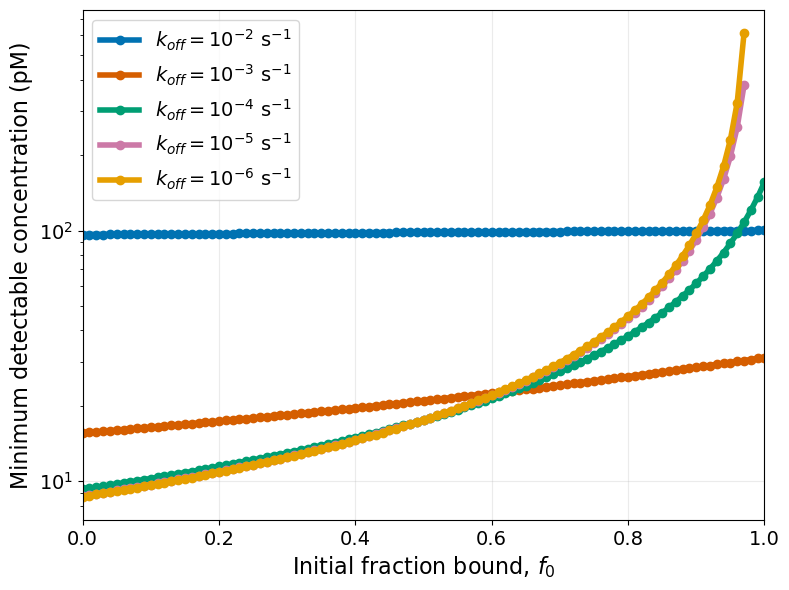

In [4]:
# ============================================================
# Plot Tmin vs f0 for each Kd
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))
plt.rcParams["font.family"] = "Arial"

COLORBLIND_COLORS = [
    "#0072B2",
    "#D55E00",
    "#009E73",
    "#CC79A7",
    "#E69F00",
]

# for koff in koff_values:
for i, koff in enumerate(koff_values):
    color = COLORBLIND_COLORS[i % len(COLORBLIND_COLORS)]

    # Kd in pM
    Kd_pM = (koff / kon) * 1e12

    # Get results for this Kd / koff
    rows = [
        row for row in results
        if np.isclose(row["koff"], koff)
    ]

    f0_this = np.array([row["f0"] for row in rows])
    Tmin_this = np.array([row["minimum_T_pM"] for row in rows])

    # Only plot finite Tmin values
    valid = np.isfinite(Tmin_this)

    ax.plot(
        f0_this[valid],
        Tmin_this[valid],
        marker="o",
        markersize=6,
        linewidth=4,
        color=color,
        # label=rf"$k_off = {koff:g}$ pM"
        label=rf"$k_{{off}} = 10^{{{int(np.log10(koff))}}}\ \mathrm{{s}}^{{-1}}$"
    )

ax.set_xlabel(
    r"Initial fraction bound, $f_0$",
    fontsize=16
)

ax.set_ylabel(
    r"Minimum detectable concentration (pM)",
    fontsize=16
)

ax.set_yscale("log")
ax.tick_params(axis="both", labelsize=14)

ax.set_xlim(0, 1)

# ax.set_title(
#     r"Minimum $[T]$ giving CRLB CV $<10\%$",
#     fontsize=18
# )

ax.grid(alpha=0.25)

ax.legend(
    # title=r"$k_off$ values",
    fontsize=14
)

plt.tight_layout()
plt.show()

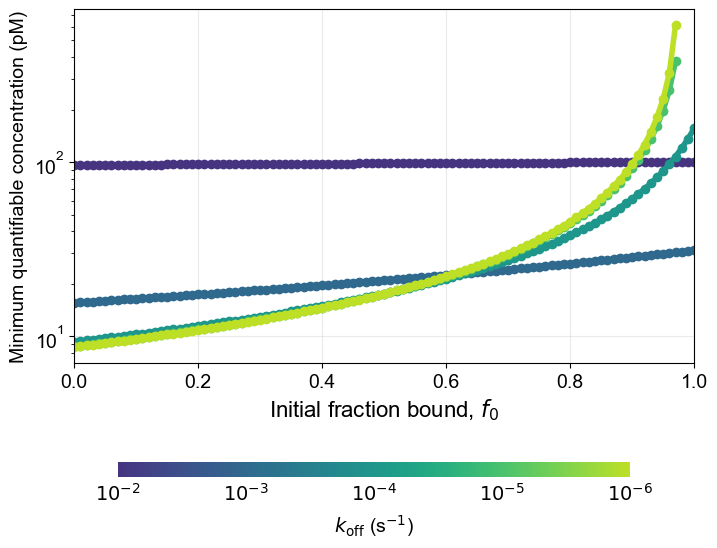

In [ ]:

# ============================================================
# Plot Tmin vs f0 for each koff
# Plasma gradient + horizontal colorbar
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable

plt.rcParams["font.family"] = "Arial"

fig, ax = plt.subplots(figsize=(8, 6))

koff_sorted = np.sort(np.asarray(koff_values, dtype=float))[::-1]

cmap = plt.cm.viridis

color_positions = np.linspace(0.15, 0.90, len(koff_sorted))

koff_to_color = {
    koff: cmap(pos)
    for koff, pos in zip(koff_sorted, color_positions)
}

# ------------------------------------------------------------
# Plot Tmin vs f0
# ------------------------------------------------------------

for koff in koff_sorted:

    color = koff_to_color[koff]

    # Kd in pM
    Kd_pM = (koff / kon) * 1e12

    # Get results for this koff
    rows = [
        row for row in results
        if np.isclose(row["koff"], koff, rtol=1e-8, atol=0)
    ]

    f0_this = np.array([row["f0"] for row in rows])
    Tmin_this = np.array([row["minimum_T_pM"] for row in rows])

    # Only plot finite, positive Tmin values
    valid = np.isfinite(f0_this) & np.isfinite(Tmin_this) & (Tmin_this > 0)

    # Sort by f0 for connected lines
    order = np.argsort(f0_this[valid])

    ax.plot(
        f0_this[valid][order],
        Tmin_this[valid][order],
        marker="o",
        markersize=6,
        linewidth=4,
        color=color,
    )

# ------------------------------------------------------------
# Axis formatting
# ------------------------------------------------------------

ax.set_xlabel(
    r"Initial fraction bound, $f_0$",
    fontsize=16
)

ax.set_ylabel(
    "Minimum quantifiable concentration (pM)",
    fontsize=14
)

ax.set_yscale("log")
ax.tick_params(axis="both", labelsize=14)
ax.set_xlim(0, 1)
ax.grid(alpha=0.25)

# ------------------------------------------------------------
# Horizontal colorbar
# ------------------------------------------------------------

# Truncated plasma gradient matching the line colors
truncated_cmap = LinearSegmentedColormap.from_list(
    "truncated_viridis",
    cmap(np.linspace(0.15, 0.90, 256))
)

sm = ScalarMappable(
    norm=Normalize(vmin=0, vmax=1),
    cmap=truncated_cmap
)
sm.set_array([])

# Leave room for the colorbar
fig.subplots_adjust(bottom=0.29)

# Colorbar placed below the plot
cax = fig.add_axes([0.18, 0.10, 0.64, 0.025])

cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal"
)

# One tick per koff
tick_positions = np.linspace(0, 1, len(koff_sorted))

cbar.set_ticks(tick_positions)

cbar.set_ticklabels([
    rf"$10^{{{int(round(np.log10(k)))}}}$"
    for k in koff_sorted
])

cbar.set_label(
    r"$k_{\mathrm{off}}$ (s$^{-1}$)",
    fontsize=14,
    labelpad=6
)

cbar.ax.tick_params(labelsize=14, length=0)
cbar.outline.set_visible(False)

plt.show()
